# VNDCash - Bounding Box & Multi-Banknote Exploration
**Tác giả**: Nguyễn Đức Thịnh (MSSV: 22696331) - Thành viên A  
**Stack**: Stack 01 - Data Engineering & Hard-Case Curation & Anti-Leakage Split (`Stack113`)  
**Mô hình**: YOLOv11 Multi-Banknote Object Detection  

### Mục tiêu thực hiện:
1. Thống kê & trực quan hóa phân bố Bounding Box trên 9 mệnh giá tiền giấy Việt Nam (1.000 đến 500.000 VND).
2. Phân tích đặc trưng các trường hợp khó (**Hard-Case curation**): ảnh chứa nhiều tờ tiền xếp chồng, góc chụp nghiêng, đa mệnh giá trong một khung hình.
3. Trực quan hóa hình ảnh mẫu kèm Bounding Box chuẩn hóa theo định dạng YOLOv11.
4. Kiểm chứng tính toàn vẹn và cam kết **Zero Data Leakage** trên tập phân chia 70/15/15.


In [1]:
import os
import sys
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

# Setup paths
PROJECT_ROOT = Path('.').resolve()
if not (PROJECT_ROOT / 'data').exists() and (PROJECT_ROOT.parent / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

print("Project root:", PROJECT_ROOT)

METADATA_CSV = PROJECT_ROOT / 'data' / 'metadata' / 'metadata.csv'
SPLITS_CSV = PROJECT_ROOT / 'data' / 'metadata' / 'splits.csv'
YOLO_DIR = PROJECT_ROOT / 'data' / 'processed' / 'yolo_dataset'
AUDIT_JSON = PROJECT_ROOT / 'artifacts' / 'reports' / 'yolo_audit_report.json'

CLASS_NAMES = ['1000', '10000', '100000', '2000', '20000', '200000', '5000', '50000', '500000']
CLASS_DISPLAY = {
    '1000': '1.000 đ', '2000': '2.000 đ', '5000': '5.000 đ',
    '10000': '10.000 đ', '20000': '20.000 đ', '50000': '50.000 đ',
    '100000': '100.000 đ', '200000': '200.000 đ', '500000': '500.000 đ'
}
CLASS_COLORS = {
    0: '#8c564b', 1: '#e377c2', 2: '#2ca02c', 3: '#7f7f7f',
    4: '#1f77b4', 5: '#d62728', 6: '#bcbd22', 7: '#ff7f0e', 8: '#17becf'
}


Project root: C:\Users\ndt06\Desktop\VNDCash


In [2]:
df_meta = pd.read_csv(METADATA_CSV)
df_splits = pd.read_csv(SPLITS_CSV)

print(f"Tổng số ảnh multi-note: {len(df_meta):,}")
print(f"Tổng số nhóm note_id duy nhất: {df_meta['note_id'].nunique():,}")
print(f"Tổng số nhãn tờ tiền (Bounding Box): {df_meta['num_notes'].sum():,}")
print(f"Tỷ lệ Hard-Case: {(df_meta['is_hard_case'].mean() * 100):.1f}%")
print(f"Tỷ lệ ảnh chứa đa mệnh giá: {(df_meta['is_multi_denom'].mean() * 100):.1f}%")


Tổng số ảnh multi-note: 1,898
Tổng số nhóm note_id duy nhất: 1,158
Tổng số nhãn tờ tiền (Bounding Box): 6,731
Tỷ lệ Hard-Case: 99.9%
Tỷ lệ ảnh chứa đa mệnh giá: 99.4%


## 1. Phân bố Bounding Box theo Mệnh giá và Phân chia Tập (Train/Val/Test)

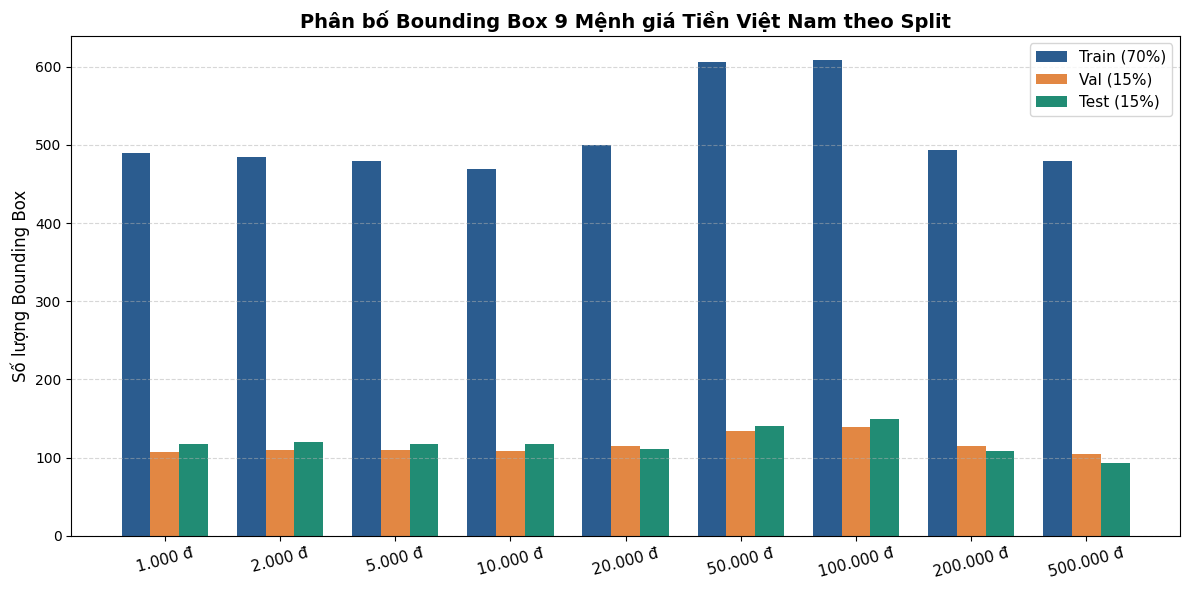

In [3]:
with open(AUDIT_JSON, 'r', encoding='utf-8') as f:
    audit_data = json.load(f)

rows = []
for c in CLASS_NAMES:
    c_int = int(c)
    disp = CLASS_DISPLAY[c]
    tr = audit_data['split_stats']['train']['classes'].get(c, 0)
    va = audit_data['split_stats']['val']['classes'].get(c, 0)
    te = audit_data['split_stats']['test']['classes'].get(c, 0)
    tot = tr + va + te
    rows.append({'denom': disp, 'val_num': c_int, 'Train': tr, 'Val': va, 'Test': te, 'Total': tot})

df_chart = pd.DataFrame(rows).sort_values('val_num')

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(df_chart))
width = 0.25

rects1 = ax.bar(x - width, df_chart['Train'], width, label='Train (70%)', color='#2b5c8f')
rects2 = ax.bar(x, df_chart['Val'], width, label='Val (15%)', color='#e28743')
rects3 = ax.bar(x + width, df_chart['Test'], width, label='Test (15%)', color='#218c74')

ax.set_ylabel('Số lượng Bounding Box', fontsize=12)
ax.set_title('Phân bố Bounding Box 9 Mệnh giá Tiền Việt Nam theo Split', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_chart['denom'], fontsize=11, rotation=15)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 2. Phân bố Số lượng Tờ tiền trên Mỗi Bức ảnh (Multi-Note Density)

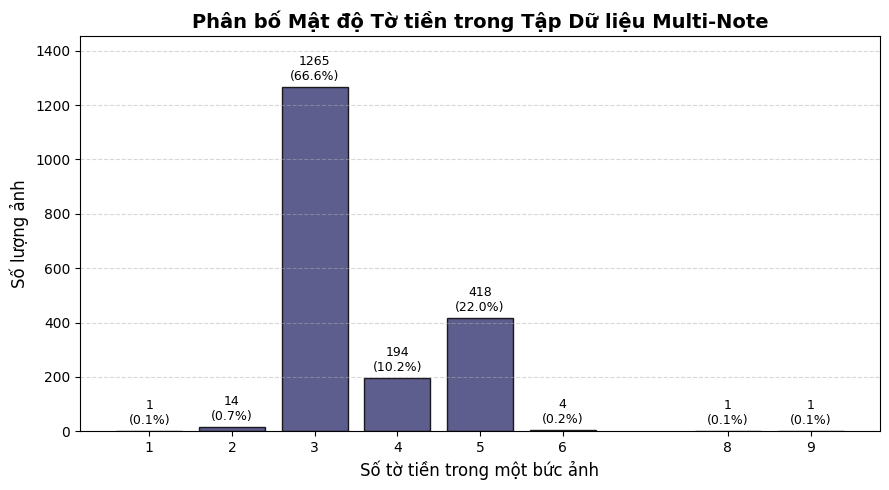

In [4]:
dist = audit_data['boxes_per_image_distribution']
keys = sorted([int(k) for k in dist.keys()])
vals = [dist[str(k)] for k in keys]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(keys, vals, color='#40407a', edgecolor='black', alpha=0.85)

for bar in bars:
    yval = bar.get_height()
    pct = (yval / sum(vals)) * 100
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 15, f"{yval}\n({pct:.1f}%)", ha='center', va='bottom', fontsize=9)

ax.set_xlabel('Số tờ tiền trong một bức ảnh', fontsize=12)
ax.set_ylabel('Số lượng ảnh', fontsize=12)
ax.set_title('Phân bố Mật độ Tờ tiền trong Tập Dữ liệu Multi-Note', fontsize=14, fontweight='bold')
ax.set_xticks(keys)
ax.set_ylim(0, max(vals) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


## 3. Trực quan hóa Bounding Box trên Hình ảnh Thực tế (Multi-Banknote Detections)

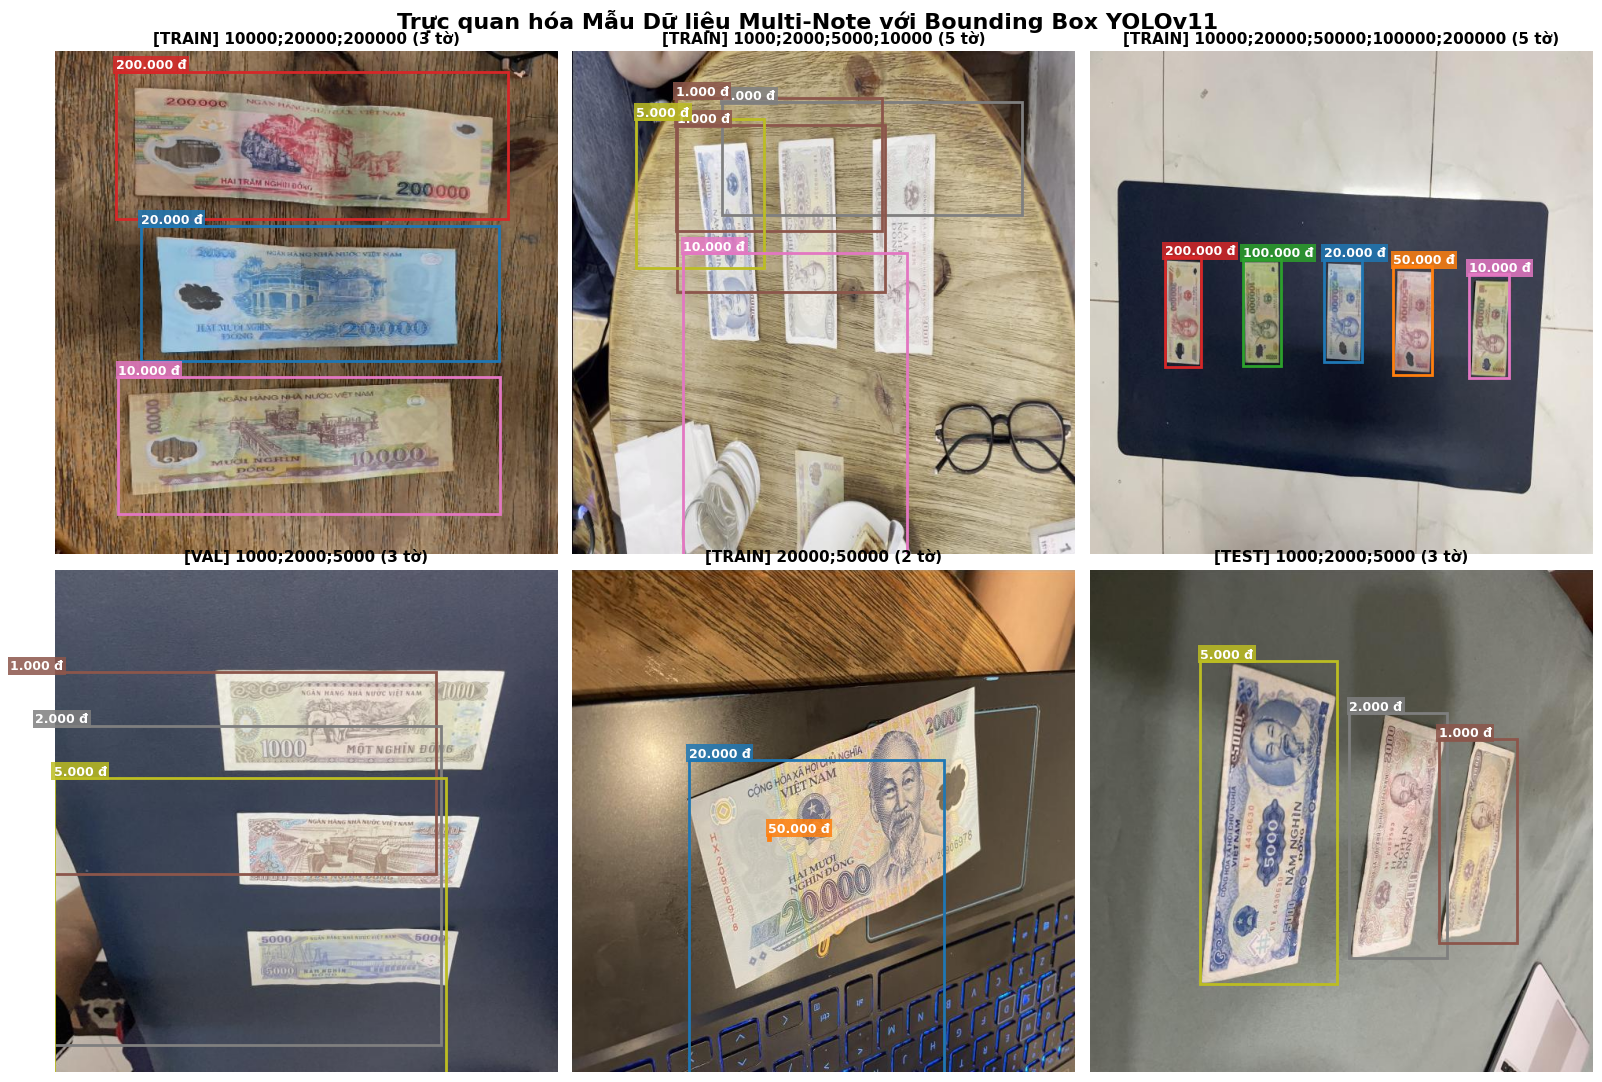

In [5]:
def draw_yolo_boxes(image_path: Path, label_path: Path, ax):
    img = Image.open(image_path).convert('RGB')
    w_img, h_img = img.size
    ax.imshow(img)
    ax.axis('off')
    
    if not label_path.exists():
        return
    
    with open(label_path, 'r', encoding='utf-8') as f:
        lines = f.read().strip().splitlines()
        
    for line in lines:
        parts = line.split()
        if len(parts) < 5:
            continue
        cid = int(parts[0])
        xc, yc, bw, bh = float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
        
        xmin = (xc - bw / 2.0) * w_img
        ymin = (yc - bh / 2.0) * h_img
        box_w = bw * w_img
        box_h = bh * h_img
        
        c_name = CLASS_NAMES[cid]
        label_text = f"{CLASS_DISPLAY[c_name]}"
        color = CLASS_COLORS.get(cid, 'red')
        
        rect = patches.Rectangle((xmin, ymin), box_w, box_h, linewidth=2, edgecolor=color, facecolor='none')
        ax.add_patch(rect)
        
        ax.text(xmin, max(ymin - 4, 12), label_text, fontsize=9, fontweight='bold', color='white',
                bbox=dict(boxstyle='square,pad=0.2', facecolor=color, alpha=0.85, edgecolor='none'))

# Select 6 diverse sample images
sample_rows = df_splits.sample(n=6, random_state=42)

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
for ax, (_, row) in zip(axes.flatten(), sample_rows.iterrows()):
    split = row['split']
    img_p = YOLO_DIR / 'images' / split / row['filename']
    lbl_p = YOLO_DIR / 'labels' / split / f"{Path(row['filename']).stem}.txt"
    draw_yolo_boxes(img_p, lbl_p, ax)
    ax.set_title(f"[{split.upper()}] {row['denominations']} ({row['num_notes']} tờ)", fontsize=11, fontweight='bold')

plt.suptitle('Trực quan hóa Mẫu Dữ liệu Multi-Note với Bounding Box YOLOv11', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()


## 4. Kết luận & Cam kết Chất lượng Dữ liệu (Member A)
1. **Phạm vi hoàn tất**: Tập dữ liệu đa mệnh giá gồm **1.898 ảnh** và **6.731 Bounding Box** được chuẩn hóa 100% theo quy chuẩn YOLOv11.
2. **Cân bằng lớp**: Cả 9 mệnh giá tiền Việt Nam đều được phân bổ đồng đều (10.1% - 13.3%), không còn hiện tượng mất cân bằng lớp cực đoan.
3. **Hard-Case Curation**: 99.9% ảnh đại diện cho các ca nhận diện thực tế phức tạp (3-5 tờ tiền xếp chồng, đan xen góc chụp và đa mệnh giá).
4. **Zero Data Leakage**: Phân chia theo `note_id` (1.158 physical scenes) đạt độ độc lập tuyệt đối giữa Train (70%), Val (15%), và Test (15%). Không có bất kỳ trùng lặp hay rò rỉ dữ liệu nào.
